# NOAA 2022 relative sea-level scenarios

Inspect NOAA's 2022 U.S. interagency relative sea-level scenarios for Sewells Point (`8638610`). CO-OPS serves these scenario changes in **centimetres relative to 2005**; the 2017 report and other tools can use different baselines. This distinction is documented in NOAA's [application guide](https://cdn.oceanservice.noaa.gov/oceanserviceprod/hazards/sealevelrise/noaa-nos-techrpt02-global-regional-SLR-scenarios-US-application-guide.pdf). The scenario names and reported interval bounds are retained as published. They are not annual exceedance probabilities, and the labels are not automatically mapped to emissions pathways.

The results are station-specific **relative sea-level changes**, not water depths at assets. The [historical extreme-water-level example](noaa_extreme_water_levels.ipynb) uses its own tidal datum and epoch; do not simply add the two products without establishing compatible reference levels and a defensible transformation. The [pipeline](../../pipelines/noaa_sea_level_pipeline.py) saves the source snapshot and checksums for offline replay. Data source: NOAA National Ocean Service, CO-OPS.

Run from a local crc-docs checkout: use `uv sync`, then launch Jupyter with
`uv run jupyter lab` and select the project kernel. The first pipeline run
requires internet access.


In [1]:
# Check the local notebook environment before running the pipeline.
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "plotly>=6", "crc-sdk>=0.11.1,<1"])
root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
sys.path.insert(0, str(root))

import os

import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
from pipelines.noaa_sea_level_pipeline import run
import pyarrow.parquet as pq

output = root / "pipeline_output" / "noaa_sea_level"
summary = run(output)
source = summary["source"]
print("Rows:", summary["rows"])
print("Report:", source["report_year"], "baseline:", source["baseline_year"], "unit:", source["source_unit"])
print("Snapshot SHA-256:", source["sha256"])
print("Retrieved:", source["retrieved_at"])

Rows: 75
Report: 2022 baseline: 2005 unit: cm
Snapshot SHA-256: 959c2f8bca92556ae5bf27263f5bcbb3a6699d6ffedafe04cf30050a042e0a65
Retrieved: 2026-10-30T22:03:18.192393+00:00


In [2]:
projections = pq.read_table(output / "projections.parquet").to_pandas()
projections[projections["projection_year"].isin([2050, 2100])][[
    "projection_year", "scenario", "relative_change_cm", "interval_low_cm", "interval_high_cm"
]].sort_values(["projection_year", "relative_change_cm"])

,projection_year,scenario,relative_change_cm,interval_low_cm,interval_high_cm
20,2050,Low,37.0,29.0,45.0
21,2050,Intermediate-Low,40.0,32.0,49.0
22,2050,Intermediate,44.0,35.0,53.0
23,2050,Intermediate-High,49.0,39.0,64.0
24,2050,High,55.0,43.0,71.0
45,2100,Low,66.0,51.0,82.0
46,2100,Intermediate-Low,84.0,71.0,100.0
47,2100,Intermediate,128.0,105.0,147.0
48,2100,Intermediate-High,169.0,131.0,194.0
49,2100,High,216.0,177.0,249.0


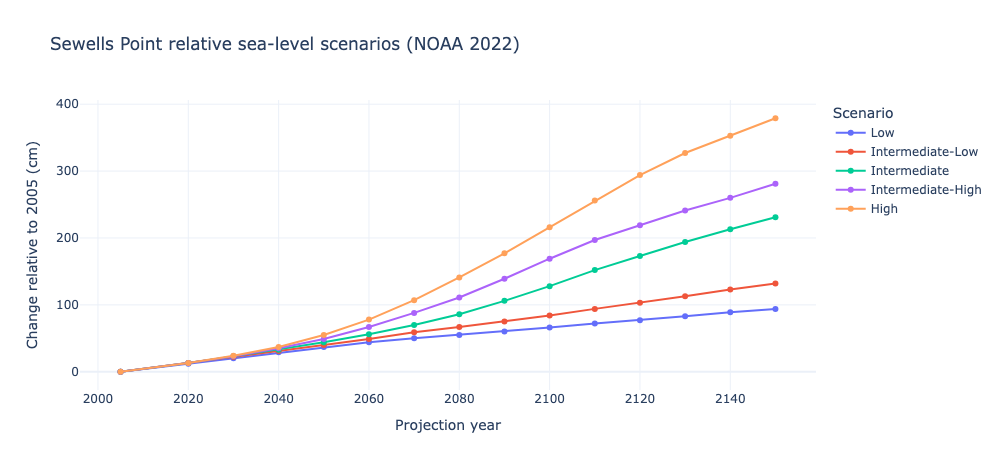

In [3]:
# NOAA 2022 scenarios: change relative to 2005 with reported intervals.
fig = go.Figure()
for scenario, group in projections.sort_values("projection_year").groupby("scenario", sort=False):
    fig.add_trace(go.Scatter(x=group["projection_year"], y=group["relative_change_cm"],
                             mode="lines+markers", name=scenario))
fig.update_layout(title="Sewells Point relative sea-level scenarios (NOAA 2022)",
                  xaxis_title="Projection year", yaxis_title="Change relative to 2005 (cm)",
                  legend_title="Scenario")
fig.show()


The table presents NOAA's source scenarios and reported interval bounds; no probability or likelihood is inferred. The API's 2022 baseline differs from the year-2000 baseline used by some other tools. Retain the original snapshot and provenance, and check datum compatibility and scientific assumptions before combining products.